# H1 robustness: the draw of the evaluation sample

The same measurement over five draws of the test split, each a different
article-level shuffle of the same corpus at the same fractions. The mined
negatives are shared unchanged, so only the choice of queries varies.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from fsr.h1_results import (
    answer_intervals,
    answer_table,
    load_axis,
    score_intervals,
    score_table,
)
from fsr.models.registry import BASE_MODELS

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {
        "figure.dpi": 100,
        "grid.linewidth": 0.6,
        "grid.alpha": 0.45,
        "axes.edgecolor": "0.3",
        "axes.linewidth": 0.9,
    }
)

BAR_FILL = sns.color_palette("pastel")[0]
BAR_EDGE = sns.color_palette("muted")[0]
MUTED_FILL = "0.88"
MUTED_EDGE = "0.6"
RULE = "0.35"
ERROR = "0.45"
D_THRESHOLDS = ((0.2, "small"), (0.5, "medium"), (0.8, "large"))

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
FIG_DIR = ROOT / "notebooks" / "h1" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save(fig, name):
    """Write the figure as a vector PDF for the thesis and a PNG to read."""
    fig.tight_layout()
    for suffix in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"{name}.{suffix}", bbox_inches="tight")


MODE = "with_body"
SPLIT = "test"
REPORTED = 42  # the draw the headline result is measured on


def seed_roots():
    """Return the corpus directory of every draw that is fully measured.

    The reported draw lives in `data/nq`; each further draw has its own root
    holding only the split files and the results. A draw whose roster is
    incomplete is left out, so the notebook reads while a sweep is still
    running.
    """
    found = {REPORTED: ROOT / "data" / "nq"}
    for path in sorted((ROOT / "data").glob("nq_s*")):
        found[int(path.name.removeprefix("nq_s"))] = path
    whole = {}
    for seed, root in found.items():
        axes = [load_axis(root, SPLIT, axis, MODE) for axis in ("cross", "within")]
        if all(len(entries) == len(BASE_MODELS) for entries in axes):
            whole[seed] = root
    return dict(sorted(whole.items(), key=lambda kv: (kv[0] != REPORTED, kv[0])))


ROOTS = seed_roots()
SEEDS = list(ROOTS)
OTHERS = [s for s in SEEDS if s != REPORTED]

cross = {s: load_axis(r, SPLIT, "cross", MODE) for s, r in ROOTS.items()}
within = {s: load_axis(r, SPLIT, "within", MODE) for s, r in ROOTS.items()}
scores = {s: score_table(e) for s, e in cross.items()}
answers = {s: answer_table(e) for s, e in within.items()}
ORDER = scores[REPORTED].index

print(f"draws measured: {', '.join(f'seed {s}' for s in SEEDS)}")
print(f"models: {len(BASE_MODELS)}   split: {SPLIT}   mode: {MODE}")

draws measured: seed 42, seed 1, seed 2, seed 3, seed 4
models: 6   split: test   mode: with_body


## The draws

The fractions fix the article count of each split, so only the record count
moves between draws.

In [2]:
def split_meta(root):
    """Return the recorded article and record counts of one draw."""
    return json.loads((root / "splits" / "meta.json").read_text())


draws = pd.DataFrame(
    {
        f"seed {s}": {
            "test articles": split_meta(r)["n_articles_test"],
            "test records": split_meta(r)["n_records_test"],
            "scored (score axis)": len(cross[s][BASE_MODELS[0].slug]["scores"]["yaml"]),
            "scored (answer axis)": within[s][BASE_MODELS[0].slug]["gold_top1"][
                "n_queries"
            ],
            "answerable": within[s][BASE_MODELS[0].slug]["conditional_inconsistency"][
                "n_answerable"
            ],
        }
        for s, r in ROOTS.items()
    }
)
draws

,seed 42,seed 1,seed 2,seed 3,seed 4
test articles,571,571,571,571,571
test records,821,812,835,781,782
scored (score axis),770,779,786,708,730
scored (answer axis),767,778,785,706,729
answerable,674,676,691,627,640


In [3]:
def test_titles(root):
    """Return the article titles the test split of one draw holds."""
    records = json.loads((root / "splits" / "test.json").read_text())["records"]
    return {r["title"] for r in records}


titles = {s: test_titles(r) for s, r in ROOTS.items()}
overlap = pd.DataFrame(
    {
        f"seed {a}": {
            f"seed {b}": round(100 * len(titles[a] & titles[b]) / len(titles[a]), 1)
            for b in SEEDS
        }
        for a in SEEDS
    }
)
pooled = len(set().union(*titles.values()))
print("pairwise overlap of test articles (%), against ~10% expected by design")
print(f"the {len(SEEDS)} draws between them cover {pooled} articles")
overlap

pairwise overlap of test articles (%), against ~10% expected by design
the 5 draws between them cover 2352 articles


,seed 42,seed 1,seed 2,seed 3,seed 4
seed 42,100.0,9.6,8.9,10.7,10.3
seed 1,9.6,100.0,8.6,8.4,11.0
seed 2,8.9,8.6,100.0,11.7,10.3
seed 3,10.7,8.4,11.7,100.0,8.6
seed 4,10.3,11.0,10.3,8.6,100.0


## Answer axis

In [4]:
def across(tables, column):
    """Return one column of a per-model table for every draw, plus its range."""
    frame = pd.DataFrame({f"seed {s}": t[column] for s, t in tables.items()})
    frame["range"] = frame.max(axis=1) - frame.min(axis=1)
    return frame


inconsistency = across(answers, "inconsistency_pct")
inconsistency.round(2)

,seed 42,seed 1,seed 2,seed 3,seed 4,range
model,,,,,,
MiniLM-L6,14.39,13.46,17.95,13.88,11.56,6.38
MiniLM-L12,11.94,11.35,11.24,8.87,9.52,3.06
bge-base,17.67,16.41,16.64,16.90,17.64,1.27
bge-v2-m3,4.66,4.95,5.79,5.04,5.01,1.13
mxbai-v1,3.75,5.16,4.92,2.92,3.79,2.24
jina-v2,4.90,5.49,3.43,4.82,5.22,2.06


In [5]:
print("conditional inconsistency, percentage points")
print(
    f"  widest spread across draws: {inconsistency['range'].max():.2f} pp "
    f"({inconsistency['range'].idxmax()})"
)
print(
    f"  narrowest:                  {inconsistency['range'].min():.2f} pp "
    f"({inconsistency['range'].idxmin()})"
)
print()
print("model ordering by inconsistency, each draw:")
for s in SEEDS:
    print(
        f"  seed {s:>2}: "
        + " > ".join(answers[s]["inconsistency_pct"].sort_values(ascending=False).index)
    )

conditional inconsistency, percentage points
  widest spread across draws: 6.38 pp (MiniLM-L6)
  narrowest:                  1.13 pp (bge-v2-m3)

model ordering by inconsistency, each draw:
  seed 42: bge-base > MiniLM-L6 > MiniLM-L12 > jina-v2 > bge-v2-m3 > mxbai-v1
  seed  1: bge-base > MiniLM-L6 > MiniLM-L12 > jina-v2 > mxbai-v1 > bge-v2-m3
  seed  2: MiniLM-L6 > bge-base > MiniLM-L12 > bge-v2-m3 > mxbai-v1 > jina-v2
  seed  3: bge-base > MiniLM-L6 > MiniLM-L12 > bge-v2-m3 > jina-v2 > mxbai-v1
  seed  4: bge-base > MiniLM-L6 > MiniLM-L12 > jina-v2 > bge-v2-m3 > mxbai-v1


## Score axis

Max |d| moves about twice as far between draws as mean |d| does, taking the
largest of ten format pairs where mean |d| averages them.

In [6]:
mean_d = across(scores, "mean_abs_d")
max_d = across(scores, "max_abs_d")
pd.concat({"mean |d|": mean_d, "max |d|": max_d}, axis=1).round(3)

mean |d|                                    max |d|                \
            seed 42 seed 1 seed 2 seed 3 seed 4  range seed 42 seed 1 seed 2   
model                                                                          
MiniLM-L6     0.496  0.453  0.444  0.491  0.497  0.053   0.903  0.837  0.819   
MiniLM-L12    0.433  0.423  0.422  0.436  0.471  0.049   0.938  0.977  0.914   
bge-base      0.191  0.139  0.170  0.184  0.217  0.078   0.383  0.324  0.366   
bge-v2-m3     0.279  0.277  0.315  0.244  0.251  0.071   0.452  0.557  0.564   
mxbai-v1      0.404  0.405  0.467  0.402  0.423  0.065   0.651  0.639  0.780   
jina-v2       0.479  0.406  0.469  0.436  0.499  0.093   0.896  0.870  0.888   

                                 
           seed 3 seed 4  range  
model                            
MiniLM-L6   0.836  0.986  0.167  
MiniLM-L12  0.878  1.166  0.288  
bge-base    0.420  0.463  0.139  
bge-v2-m3   0.443  0.467  0.121  
mxbai-v1    0.673  0.713  0.141  
jina-v2     0.814  0.908  0.095

In [7]:
print("format pair producing max |d|, each draw:")
pd.DataFrame({f"seed {s}": t["max_d_pair"] for s, t in scores.items()})

format pair producing max |d|, each draw:


,seed 42,seed 1,seed 2,seed 3,seed 4
model,,,,,
MiniLM-L6,yaml - toml,yaml - toml,yaml - inline_kv,yaml - toml,yaml - toml
MiniLM-L12,yaml - toml,yaml - toml,yaml - toml,yaml - toml,yaml - toml
bge-base,json - inline_kv,json - markdown,json - markdown,json - markdown,json - markdown
bge-v2-m3,yaml - inline_kv,yaml - inline_kv,yaml - inline_kv,toml - markdown,yaml - inline_kv
mxbai-v1,yaml - toml,yaml - json,toml - inline_kv,yaml - toml,yaml - toml
jina-v2,yaml - inline_kv,yaml - inline_kv,yaml - inline_kv,yaml - inline_kv,yaml - inline_kv


## Spread across draws

One marker per draw, with the reported draw picked out.

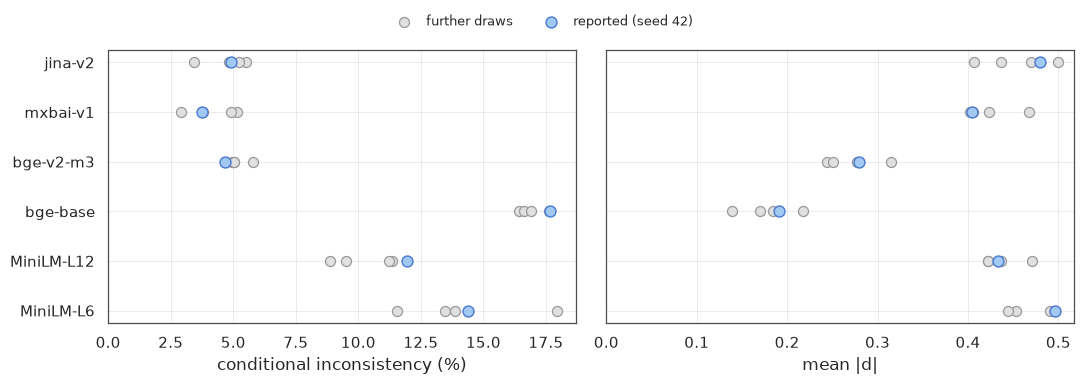

In [8]:
def spread(ax, frame, label):
    """Draw one marker per draw for each model, reported draw highlighted."""
    y = np.arange(len(ORDER))
    rows = frame.loc[ORDER]
    for offset, seed in enumerate(OTHERS):
        ax.scatter(
            rows[f"seed {seed}"],
            y,
            s=52,
            color=MUTED_FILL,
            edgecolor=MUTED_EDGE,
            linewidth=0.9,
            zorder=2,
            label="further draws" if offset == 0 else None,
        )
    ax.scatter(
        rows[f"seed {REPORTED}"],
        y,
        s=62,
        color=BAR_FILL,
        edgecolor=BAR_EDGE,
        linewidth=1.0,
        zorder=3,
        label=f"reported (seed {REPORTED})",
    )
    ax.set_yticks(y)
    ax.set_yticklabels(ORDER)
    ax.set_xlabel(label)
    ax.set_xlim(0, None)


fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
spread(left, inconsistency, "conditional inconsistency (%)")
spread(right, mean_d, "mean |d|")
fig.legend(
    *left.get_legend_handles_labels(),
    loc="upper center",
    bbox_to_anchor=(0.5, 1.08),
    ncol=2,
    frameon=False,
    fontsize=9,
)
save(fig, "seed_sweep_spread")
None

## The two axes together

The single-draw characterisation places each model in the plane of its two
measures. Adding the other four turns each point into a cross spanning what
the draws covered.

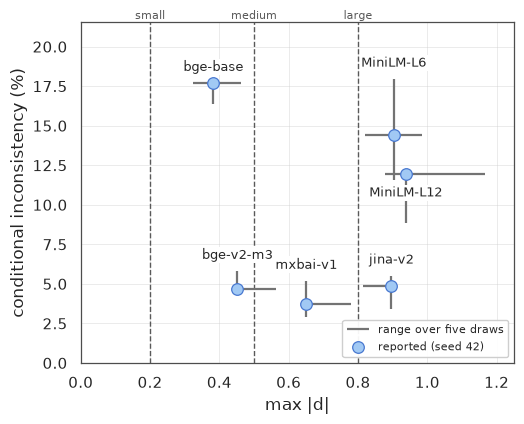

In [9]:
plane = {
    s: scores[s][["max_abs_d"]].join(answers[s][["inconsistency_pct"]]) for s in SEEDS
}
reported = plane[REPORTED]
clusters = {
    m: pd.DataFrame([plane[s].loc[m] for s in SEEDS], index=SEEDS) for m in ORDER
}

# Labels hang above the model's own range bar, as they hang above the point in
# the single-draw figure this one is read against. MiniLM-L12 is the exception:
# above would put it on MiniLM-L6's bar, so it hangs under its own point.
PLACEMENT = {
    "bge-base": ("top", 9),
    "MiniLM-L6": ("top", 9),
    "MiniLM-L12": ("point", -16),
    "bge-v2-m3": ("top", 9),
    "mxbai-v1": ("top", 9),
    "jina-v2": ("top", 9),
}

fig, ax = plt.subplots(figsize=(5.4, 4.4))
for level, name in D_THRESHOLDS:
    ax.axvline(level, color=RULE, ls="--", lw=1, zorder=1)
    ax.text(
        level,
        1.01,
        name,
        color=RULE,
        fontsize=8,
        ha="center",
        transform=ax.get_xaxis_transform(),
    )

# A cross through the reported point spanning what the five draws covered.
# Plotting each draw instead puts fifteen markers in the lower band, where
# three models share the same region and the points stop being separable.
for offset, model in enumerate(ORDER):
    rows = clusters[model]
    point = reported.loc[model]
    ax.hlines(
        point["inconsistency_pct"],
        rows["max_abs_d"].min(),
        rows["max_abs_d"].max(),
        color=ERROR,
        lw=1.6,
        zorder=2,
        label="range over five draws" if offset == 0 else None,
    )
    ax.vlines(
        point["max_abs_d"],
        rows["inconsistency_pct"].min(),
        rows["inconsistency_pct"].max(),
        color=ERROR,
        lw=1.6,
        zorder=2,
    )

ax.scatter(
    reported["max_abs_d"],
    reported["inconsistency_pct"],
    s=70,
    color=BAR_FILL,
    edgecolor=BAR_EDGE,
    linewidth=0.9,
    zorder=4,
    label=f"reported (seed {REPORTED})",
)

for model in ORDER:
    anchor, dy = PLACEMENT[model]
    y = clusters[model]["inconsistency_pct"]
    edge = {
        "top": y.max(),
        "bottom": y.min(),
        "point": reported.loc[model, "inconsistency_pct"],
    }[anchor]
    ax.annotate(
        model,
        (reported.loc[model, "max_abs_d"], edge),
        textcoords="offset points",
        xytext=(0, dy),
        ha="center",
        fontsize=9,
        bbox={"facecolor": "white", "edgecolor": "none", "pad": 1},
        zorder=5,
    )

ax.set_xlabel("max |d|")
ax.set_ylabel("conditional inconsistency (%)")
ax.set_xlim(0, 1.25)
ax.set_ylim(0, max(f["inconsistency_pct"].max() for f in plane.values()) * 1.2)
ax.legend(
    loc="lower right",
    fontsize=8,
    frameon=True,
    facecolor="white",
    edgecolor="0.8",
    framealpha=0.95,
).set_zorder(6)
save(fig, "seed_sweep_both_axes")
None

## Coverage of the reported intervals

The intervals published with the headline result are bootstrapped from the
reported draw alone, so a redraw of the evaluation sample is the variation
they stand in for. Each further draw tests them, and should fall inside about
nineteen times in twenty.

In [10]:
def coverage(builder, entries, statistic):
    """Test each further draw against the interval of the reported draw."""
    reported = builder(entries[REPORTED])
    frame = pd.DataFrame(
        {
            "reported": reported[statistic],
            "low": reported["low"],
            "high": reported["high"],
        }
    )
    inside = pd.DataFrame(
        {
            f"seed {s}": builder(entries[s])[statistic].between(
                reported["low"], reported["high"]
            )
            for s in OTHERS
        }
    )
    frame["draws inside"] = inside.sum(axis=1).astype(str) + f" / {len(OTHERS)}"
    for s in OTHERS:
        frame[f"seed {s}"] = builder(entries[s])[statistic]
    return frame, inside


score_cov, score_inside = coverage(score_intervals, cross, "max_abs_d")
answer_cov, answer_inside = coverage(answer_intervals, within, "inconsistency_pct")

print(
    f"score axis, max |d|:   {int(score_inside.values.sum())} / "
    f"{score_inside.size} further draws inside the reported 95% interval"
)
print(
    f"answer axis, incons.%: {int(answer_inside.values.sum())} / "
    f"{answer_inside.size} further draws inside the reported 95% interval"
)
score_cov.round(3)

score axis, max |d|:   18 / 24 further draws inside the reported 95% interval
answer axis, incons.%: 20 / 24 further draws inside the reported 95% interval


,reported,low,high,draws inside,seed 1,seed 2,seed 3,seed 4
model,,,,,,,,
MiniLM-L6,0.903,0.799,1.060,4 / 4,0.837,0.819,0.836,0.986
MiniLM-L12,0.938,0.852,1.039,3 / 4,0.977,0.914,0.878,1.166
bge-base,0.383,0.321,0.452,3 / 4,0.324,0.366,0.420,0.463
bge-v2-m3,0.452,0.411,0.538,2 / 4,0.557,0.564,0.443,0.467
mxbai-v1,0.651,0.603,0.747,3 / 4,0.639,0.780,0.673,0.713
jina-v2,0.896,0.826,0.999,3 / 4,0.870,0.888,0.814,0.908


In [11]:
answer_cov.round(2)

,reported,low,high,draws inside,seed 1,seed 2,seed 3,seed 4
model,,,,,,,,
MiniLM-L6,14.39,11.80,17.09,2 / 4,13.46,17.95,13.88,11.56
MiniLM-L12,11.94,9.57,14.35,2 / 4,11.35,11.24,8.87,9.52
bge-base,17.67,14.88,20.58,4 / 4,16.41,16.64,16.90,17.64
bge-v2-m3,4.66,3.15,6.25,4 / 4,4.95,5.79,5.04,5.01
mxbai-v1,3.75,2.41,5.24,4 / 4,5.16,4.92,2.92,3.79
jina-v2,4.90,3.38,6.52,4 / 4,5.49,3.43,4.82,5.22


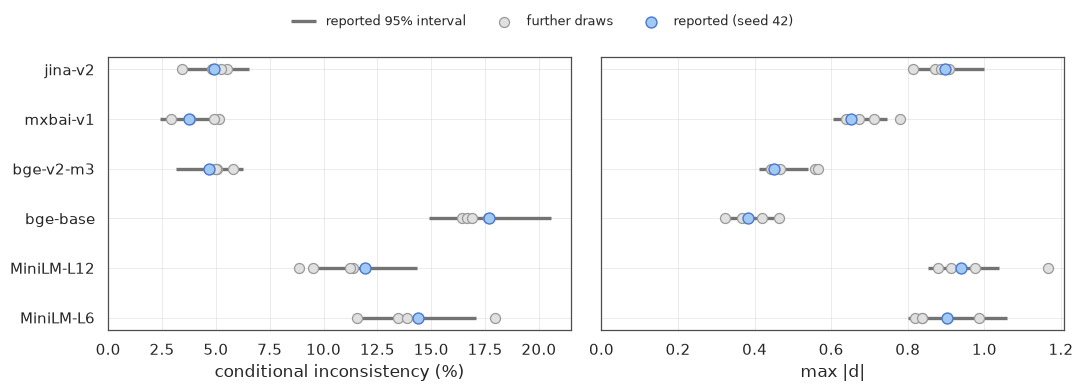

In [12]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, frame, label in (
    (left, answer_cov, "conditional inconsistency (%)"),
    (right, score_cov, "max |d|"),
):
    y = np.arange(len(ORDER))
    rows = frame.loc[ORDER]
    ax.hlines(
        y,
        rows["low"],
        rows["high"],
        color=ERROR,
        lw=2.4,
        zorder=1,
        label="reported 95% interval",
    )
    for offset, seed in enumerate(OTHERS):
        ax.scatter(
            rows[f"seed {seed}"],
            y,
            s=52,
            color=MUTED_FILL,
            edgecolor=MUTED_EDGE,
            linewidth=0.9,
            zorder=3,
            label="further draws" if offset == 0 else None,
        )
    ax.scatter(
        rows["reported"],
        y,
        s=62,
        color=BAR_FILL,
        edgecolor=BAR_EDGE,
        linewidth=1.0,
        zorder=4,
        label=f"reported (seed {REPORTED})",
    )
    ax.set_yticks(y)
    ax.set_yticklabels(ORDER)
    ax.set_xlabel(label)
    ax.set_xlim(0, None)
fig.legend(
    *left.get_legend_handles_labels(),
    loc="upper center",
    bbox_to_anchor=(0.5, 1.10),
    ncol=3,
    frameon=False,
    fontsize=9,
)
save(fig, "seed_sweep_coverage")
None

## Findings

The three most inconsistent models are the same three in every draw, and the
groups do not meet: the weakest of the three reaches 8.87% and the strongest
of the other three reaches 5.79%. Order within each group moves, but no draw
moves a model between them.

One reported claim does not survive. Both BGE models are recorded as falling
below the medium-effect threshold on the score axis, and bge-v2-m3 clears it
on two of the five draws, at 0.557 and 0.564, on the same yaml-inline_kv pair
each time. bge-base holds below it in every draw, reaching 0.463 at most.

Max |d| is the least stable statistic measured here, its range reaching 0.288
on MiniLM-L12 against a median of 0.068 for mean |d|. The reported headline
of 0.94 is its value on one draw.

Coverage of the reported intervals is 18 of 24 on max |d| and 20 of 24 on
conditional inconsistency, against a nominal 95%. The misses run in both
directions, so the intervals are too narrow rather than displaced. Both
resample records while the split is drawn by article.

The draws are not independent samples. Each test split is a tenth of one
fixed corpus and the five together cover 2,352 of its 5,703 articles, so they
bound the dependence on which tenth was held out rather than generalisation
to a new corpus.